# Task 15, Notebook 13: Models, cross-validation, tuning and accuracy

**Programme:** Aura Workforce by Growmar, AI/ML track, CortexHR **Phase 3: Intelligence**  
**Task:** 15: Recommend fair pay bands  
**Objective:** Compare a simple baseline, a linear model and gradient boosting, with MAE and R2, then evaluate once on the test set.  
**Workflow stages covered in this notebook:** 22, 23, 24, 25, 26, 27, 28, 29, 30, 31 of the 38-stage Phase 1/2 standard.  
**Rule for every number below:** it is printed by the code in the same notebook; nothing is typed in by hand.

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'config' / 'phase3_config.yaml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from cortexhr.phase3.common.config import load_config
from cortexhr.phase3.common import paths as P
CFG = load_config(); SEED = CFG['seed']
print('project root:', ROOT.name, '| seed:', SEED)

project root: phase3_working | seed: 42


In [2]:
from cortexhr.phase3.common.io import read_csv, save_table, save_json
from cortexhr.phase3.common.validation import profile
from cortexhr.phase3.salary import model as S, run as SR
from cortexhr.phase3.explanations.risk_report import load_helpers
H = load_helpers()
sal = read_csv('salary_training'); df = S.load_salary(); dd = read_csv('data_dictionary')
print('salary rows:', sal.shape, '| engineered:', df.shape)

salary rows: (2934, 17) | engineered: (2934, 20)


## Stage 22: Data Preprocessing

*What this stage is for:* Cleaning and encoding, fitted on training data only.

Scaling and one-hot encoding are inside the sklearn pipeline, learned on each training fold only. Rare categories (fewer than 5) are grouped; unseen categories are ignored.

In [3]:
S.preprocessor(S.JOB_FEATURES).fit(df.iloc[:2000][S.JOB_FEATURES]).transform(df.iloc[2000:][S.JOB_FEATURES]).shape

(934, 98)

## Stage 23: Train, Validation and Test Strategy

*What this stage is for:* How data is split so no result is measured on data the model has seen.

80% training / 20% test (seed 42); 5-fold cross-validation inside the training part; the test set is used once.

In [4]:
tr, te = S.split(df); print('train', len(tr), '| test', len(te), '| folds', CFG['salary']['n_splits'])

train 2347 | test 587 | folds 5


## Stage 24: Baseline Establishment

*What this stage is for:* The simple method every model must beat.

Baselines: (1) the task's simple 'average offered salary by role'; (2) a stronger reference, the role average adjusted for the market index, to show honestly how much the models add beyond what a careful clerk could do.

## Stage 25: Model Selection and Justification

*What this stage is for:* Why these candidate methods.

Linear regression (Ridge) because it is transparent; gradient boosting because pay may depend on interactions. Both predict the log salary.

## Stage 26: Model Training

*What this stage is for:* Fit the candidates.

In [5]:
import time; t = time.time(); o = SR.run_task15(write=True); print('Task 15 pipeline finished in %.0f s | final model: %s' % (time.time() - t, o['final_model']))

Task 15 pipeline finished in 11 s | final model: Ridge regression (job-related features)


## Stage 27: Cross-Validation

*What this stage is for:* Repeat the evaluation on several splits to see the spread.

Cross-validated accuracy on the training part (out-of-fold predictions).

In [6]:
cv = o['cv_metrics'].round(3); cv

                                                    MAE_rupees  RMSE_rupees     R2  median_abs_pct_error  MAE_log
baseline: average offered salary by role            115963.777   176580.641  0.924                12.509    0.141
baseline 2: role average adjusted for market index   54898.290    88556.905  0.981                 5.435    0.066
Ridge regression (job-related features)              54401.464    87685.585  0.981                 5.402    0.065
Ridge regression + career_gap_months                 54221.023    87538.023  0.981                 5.360    0.065
Gradient boosting (job-related features, tuned)      55567.041    89878.866  0.980                 5.484    0.067
Gradient boosting + career_gap_months                55450.617    89617.441  0.980                 5.489    0.067

## Stage 28: Hyperparameter Tuning

*What this stage is for:* A small, logged search; no tuning on the test set.

Six gradient-boosting settings; the lowest cross-validated MAE is selected. Differences are small, so no more tuning is justified.

In [7]:
o['tuning_log'][['experiment_id', 'params', 'MAE_rupees', 'R2', 'decision']].round(3)

  experiment_id                                                                            params  MAE_rupees     R2                  decision
0           S00  {'learning_rate': 0.05, 'max_iter': 200, 'max_depth': 2, 'min_samples_leaf': 20}   55803.062  0.980              not selected
1           S01  {'learning_rate': 0.05, 'max_iter': 300, 'max_depth': 3, 'min_samples_leaf': 20}   55567.041  0.980  selected (lowest CV MAE)
2           S02  {'learning_rate': 0.03, 'max_iter': 400, 'max_depth': 3, 'min_samples_leaf': 40}   57716.950  0.978              not selected
3           S03  {'learning_rate': 0.08, 'max_iter': 150, 'max_depth': 3, 'min_samples_leaf': 20}   55729.309  0.980              not selected
4           S04  {'learning_rate': 0.05, 'max_iter': 300, 'max_depth': 4, 'min_samples_leaf': 30}   57791.334  0.978              not selected
5           S05   {'learning_rate': 0.1, 'max_iter': 100, 'max_depth': 2, 'min_samples_leaf': 20}   56098.918  0.980              not selected

## Stage 29: Model Evaluation

*What this stage is for:* Metrics suited to the problem, against the baseline.

Test set, used once, with the models fitted on the training part. MAE and R2 for each model against the baselines.

In [8]:
tm = o['test_metrics'].round(3); tm

                                                    MAE_rupees  RMSE_rupees     R2  median_abs_pct_error  MAE_log
baseline: average offered salary by role            115094.237   167820.719  0.933                12.769    0.140
baseline 2: role average adjusted for market index   55656.281    88203.649  0.982                 5.521    0.066
Ridge regression (job-related features)              53924.807    84330.025  0.983                 5.397    0.065
Gradient boosting (job-related features, tuned)      57504.058    93722.100  0.979                 5.731    0.068
Ridge regression + career_gap_months                 53160.626    83054.131  0.984                 5.451    0.064
Gradient boosting + career_gap_months                56955.579    92902.114  0.980                 5.657    0.067

In [9]:
b1, b2 = tm.loc['baseline: average offered salary by role'], tm.loc['baseline 2: role average adjusted for market index']; f = tm.loc[o['final_model']]
print('Final model %s: MAE Rs %.0f, R2 %.3f' % (o['final_model'], f.MAE_rupees, f.R2)); print('vs role-average baseline: MAE %.0f%% lower; vs market-adjusted role baseline: MAE %.0f%% lower' % (100 * (1 - f.MAE_rupees / b1.MAE_rupees), 100 * (1 - f.MAE_rupees / b2.MAE_rupees)))
print('success criterion "beat the simple baseline":', bool(f.MAE_rupees < b1.MAE_rupees))

Final model Ridge regression (job-related features): MAE Rs 53925, R2 0.983
vs role-average baseline: MAE 53% lower; vs market-adjusted role baseline: MAE 3% lower
success criterion "beat the simple baseline": True


## Stage 30: Error and Misclassification Analysis

*What this stage is for:* Look at the cases the model gets wrong and say why.

Where is the model wrong? Largest test errors and error by job level.

           count  median  mean
job_level                     
1            158     5.4   6.4
2            191     6.3   7.2
3            139     4.4   5.8
4             74     4.9   6.2
5             25     6.2   7.0


       hire_id role_id  job_level  prior_experience_years  offered_annual_fixed       pred  abs_pct_err
446  HIRE-2200    R015          1                     1.5                260952   342570.8         31.3
113   EMP-0414    R055          2                     3.2                482628   621291.4         28.7
129  HIRE-1862    R007          4                     6.9               1786500  2194432.8         22.8
110  HIRE-1599    R002          1                     0.5                318276   390132.5         22.6
415   EMP-0545    R052          3                     2.9                645456   786469.9         21.8

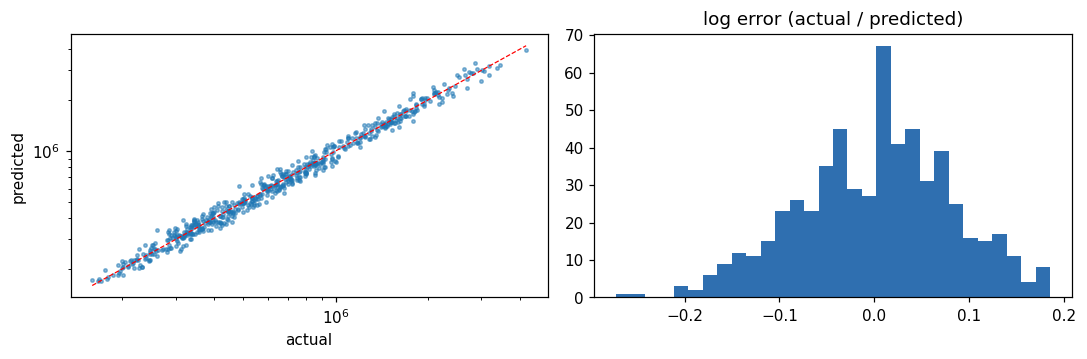

In [10]:
te = o['test'].copy(); te['pred'] = o['test_pred'][o['final_model']]; te['abs_pct_err'] = (te.offered_annual_fixed - te.pred).abs() / te.offered_annual_fixed * 100
print(te.groupby('job_level').abs_pct_err.agg(['count', 'median', 'mean']).round(1).to_string())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); ax[0].scatter(te.offered_annual_fixed, te.pred, s=5, alpha=.5); lim = [te.offered_annual_fixed.min(), te.offered_annual_fixed.max()]; ax[0].plot(lim, lim, 'r--', lw=.8); ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('actual'); ax[0].set_ylabel('predicted')
ax[1].hist(np.log(te.offered_annual_fixed / te.pred), bins=30, color='#2f6fb0'); ax[1].set_title('log error (actual / predicted)'); plt.tight_layout()
te.sort_values('abs_pct_err', ascending=False).head(5)[['hire_id', 'role_id', 'job_level', 'prior_experience_years', 'offered_annual_fixed', 'pred', 'abs_pct_err']].round(1)

## Stage 31: Explainability and Feature Importance

*What this stage is for:* What drives the output, in plain words.

What moves the recommendation? Coefficients of the linear model on the standardised numeric inputs (percent change in salary for a one-standard-deviation change), and permutation importance for the chosen model.

In [11]:
rg = o['fitted']['Ridge regression (job-related features)']; names = rg.named_steps['prep'].get_feature_names_out(); coef = pd.Series(rg.named_steps['model'].coef_, index=names)
num = coef[[c for c in coef.index if c.startswith('num__')]].rename(lambda c: c.replace('num__', '')); (np.expm1(num) * 100).round(2).sort_values(ascending=False).to_frame('% change in salary per +1 sd')

                        % change in salary per +1 sd
log_band_mid                                   76.64
log_market_index                               16.18
job_level                                       4.61
prior_experience_years                          3.30
skills_count                                   -0.17

                        importance
log_band_mid                0.6022
log_market_index            0.1129
department_id               0.0163
job_level                   0.0157
prior_experience_years      0.0085
role_id                     0.0018
highest_education           0.0010
skills_count                0.0001
work_location              -0.0000

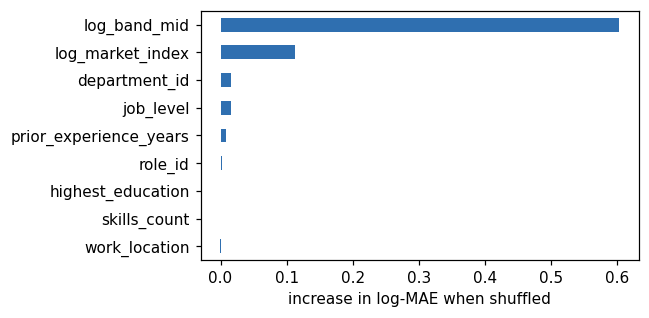

In [12]:
from sklearn.inspection import permutation_importance
mdl = o['fitted'][o['final_model']]; Xte_ = o['test'][S.JOB_FEATURES]; yl = np.log(o['test'][S.TARGET].to_numpy(float))
pi = permutation_importance(mdl, Xte_, yl, scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=S.JOB_FEATURES).sort_values(ascending=False); fig, ax = plt.subplots(figsize=(6, 3)); imp[::-1].plot.barh(ax=ax, color='#2f6fb0'); ax.set_xlabel('increase in log-MAE when shuffled'); plt.tight_layout(); imp.round(4).to_frame('importance')